In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
from scipy import stats
import types

In [2]:
pd.set_option('display.float_format', '{:.3f}'.format)

In [3]:
import os
path = '' #local

custom_functions = [
    name for name, obj in globals().items()
    if isinstance(obj, types.FunctionType) and obj.__module__ == '__main__'
]

In [4]:
os.chdir(path)

In [5]:
data = pd.read_csv('credit_risk_dataset.csv')

In [6]:
loan_data = data.copy()

In [7]:
loan_data.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.000,PERSONAL,D,35000,16.020,1,0.590,Y,3
1,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0,0.100,N,2
2,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,1,0.570,N,3
3,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,1,0.530,N,2
4,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,1,0.550,Y,4


In [8]:
loan_data['cb_person_default_on_file'] = loan_data['cb_person_default_on_file'].map({'Y': 1, 'N':0})

In [9]:
loan_data['loan_status'] = np.where(loan_data['loan_status'] == 0,1,0)
loan_data
# 1: Non-default , 0: Default

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.000,PERSONAL,D,35000,16.020,0,0.590,1,3
1,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,1,0.100,0,2
2,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,0,0.570,0,3
3,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,0,0.530,0,2
4,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,0,0.550,1,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32576,57,53000,MORTGAGE,1.000,PERSONAL,C,5800,13.160,1,0.110,0,30
32577,54,120000,MORTGAGE,4.000,PERSONAL,A,17625,7.490,1,0.150,0,19
32578,65,76000,RENT,3.000,HOMEIMPROVEMENT,B,35000,10.990,0,0.460,0,28
32579,56,150000,MORTGAGE,5.000,PERSONAL,B,15000,11.480,1,0.100,0,26


<Axes: >

<Figure size 2000x600 with 0 Axes>

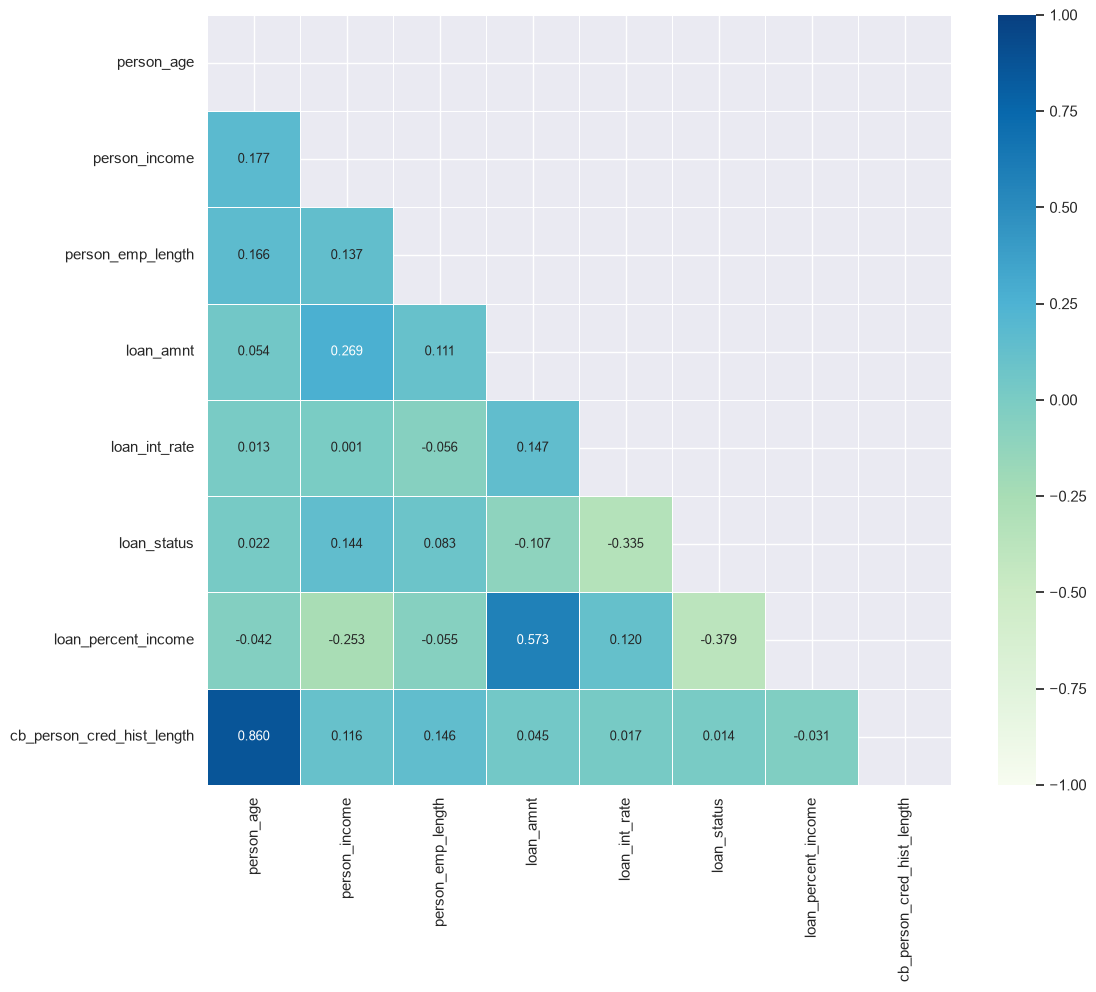

In [22]:
plt.figure(figsize=(20,6))
mask = np.triu(np.ones_like(loan_data[loan_data['loan_int_rate'].notnull()].loc[:, list(i for i in list(loan_data.columns.values) 
            if i not in ['person_home_ownership','loan_intent','loan_grade'] and i != 'cb_person_default_on_file')].corr()
,dtype= bool))
f, ax = plt.subplots(figsize=(12,10))
sns.set_theme(style='white')
sns.heatmap(loan_data[loan_data['loan_int_rate'].notnull()].loc[:, list(i for i in list(loan_data.columns.values) 
            if i not in ['person_home_ownership','loan_intent','loan_grade'] and i != 'cb_person_default_on_file')].corr(),
            cmap= 'GnBu', linewidths= 0.5, mask=mask, vmax=1, vmin=-1, annot=True, fmt='.3f', annot_kws={"fontsize": 9})


# Continuous variables correlation matrix

In [76]:
loan_data.info() 

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  int64  
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(6), str(3)
memory usage: 3.5 MB


In [77]:
loan_data.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
count,32581.000,32581.000,31686.000,32581.000,29465.000,32581.000,32581.000,32581.000,32581.000
mean,27.735,66074.848,4.790,9589.371,11.012,0.782,0.170,0.176,5.804
std,6.348,61983.119,4.143,6322.087,3.240,0.413,0.107,0.381,4.055
min,20.000,4000.000,0.000,500.000,5.420,0.000,0.000,0.000,2.000
25%,23.000,38500.000,2.000,5000.000,7.900,1.000,0.090,0.000,3.000
50%,26.000,55000.000,4.000,8000.000,10.990,1.000,0.150,0.000,4.000
75%,30.000,79200.000,7.000,12200.000,13.470,1.000,0.230,0.000,8.000
max,144.000,6000000.000,123.000,35000.000,23.220,1.000,0.830,1.000,30.000


### Drop outliers

In [78]:
loan_data = loan_data.drop(loan_data[loan_data['person_age'] > 100].index)
loan_data = loan_data.drop(loan_data[loan_data['person_emp_length']>60].index)
loan_data = loan_data.reset_index(drop=True)

In [79]:
loan_data

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,1,0.100,0,2
1,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,0,0.570,0,3
2,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,0,0.530,0,2
3,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,0,0.550,1,4
4,21,9900,OWN,2.000,VENTURE,A,2500,7.140,0,0.250,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32569,57,53000,MORTGAGE,1.000,PERSONAL,C,5800,13.160,1,0.110,0,30
32570,54,120000,MORTGAGE,4.000,PERSONAL,A,17625,7.490,1,0.150,0,19
32571,65,76000,RENT,3.000,HOMEIMPROVEMENT,B,35000,10.990,0,0.460,0,28
32572,56,150000,MORTGAGE,5.000,PERSONAL,B,15000,11.480,1,0.100,0,26


### Null values

In [80]:
loan_data['person_emp_length'] = loan_data['person_emp_length'].fillna(0)

In [81]:
loan_data['person_emp_length'].isnull().sum()

np.int64(0)

In [82]:
loan_data[loan_data['loan_int_rate'].isnull()]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
38,23,71500,RENT,3.000,DEBTCONSOLIDATION,D,30000,NaN,0,0.420,0,4
49,24,78000,RENT,4.000,DEBTCONSOLIDATION,D,30000,NaN,0,0.380,1,4
56,23,277000,OWN,3.000,PERSONAL,A,35000,NaN,1,0.130,0,4
58,24,12000,OWN,2.000,VENTURE,E,1750,NaN,1,0.150,1,3
61,26,263000,MORTGAGE,0.000,EDUCATION,B,10000,NaN,0,0.040,0,4
...,...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,OWN,0.000,VENTURE,C,1400,NaN,0,0.290,1,28
32545,65,45900,RENT,2.000,EDUCATION,C,10000,NaN,1,0.220,1,19
32546,54,20000,RENT,2.000,MEDICAL,C,5000,NaN,1,0.250,0,28
32562,51,60000,MORTGAGE,1.000,PERSONAL,A,7500,NaN,1,0.130,0,23


In [83]:
loan_data

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,1,0.100,0,2
1,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,0,0.570,0,3
2,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,0,0.530,0,2
3,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,0,0.550,1,4
4,21,9900,OWN,2.000,VENTURE,A,2500,7.140,0,0.250,0,2
...,...,...,...,...,...,...,...,...,...,...,...,...
32569,57,53000,MORTGAGE,1.000,PERSONAL,C,5800,13.160,1,0.110,0,30
32570,54,120000,MORTGAGE,4.000,PERSONAL,A,17625,7.490,1,0.150,0,19
32571,65,76000,RENT,3.000,HOMEIMPROVEMENT,B,35000,10.990,0,0.460,0,28
32572,56,150000,MORTGAGE,5.000,PERSONAL,B,15000,11.480,1,0.100,0,26


In [84]:
reorder = loan_data.pop('loan_status')

In [85]:
loan_data.insert(loc=loan_data.shape[1], column='loan_status', value=reorder)

### Imputing null using Decision tree

In [86]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

In [87]:
df_predict_dcr = loan_data[loan_data['loan_int_rate'].isnull()]

In [88]:
df_predict_dcr = df_predict_dcr.drop('loan_status', axis = 1)

In [89]:
df_predict_dcr

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
38,23,71500,RENT,3.000,DEBTCONSOLIDATION,D,30000,NaN,0.420,0,4
49,24,78000,RENT,4.000,DEBTCONSOLIDATION,D,30000,NaN,0.380,1,4
56,23,277000,OWN,3.000,PERSONAL,A,35000,NaN,0.130,0,4
58,24,12000,OWN,2.000,VENTURE,E,1750,NaN,0.150,1,3
61,26,263000,MORTGAGE,0.000,EDUCATION,B,10000,NaN,0.040,0,4
...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,OWN,0.000,VENTURE,C,1400,NaN,0.290,1,28
32545,65,45900,RENT,2.000,EDUCATION,C,10000,NaN,0.220,1,19
32546,54,20000,RENT,2.000,MEDICAL,C,5000,NaN,0.250,0,28
32562,51,60000,MORTGAGE,1.000,PERSONAL,A,7500,NaN,0.130,0,23


In [90]:
df_train_dcr = loan_data[loan_data['loan_int_rate'].notnull()]
df_train_dcr = df_train_dcr.drop('loan_status', axis = 1)

In [91]:
df_train_dcr.tail(15)

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
32557,53,45000,RENT,0.000,PERSONAL,C,5600,13.790,0.120,0,28
32558,57,40000,RENT,1.000,MEDICAL,A,15000,8.900,0.380,0,21
32559,52,30000,RENT,6.000,VENTURE,C,5000,12.730,0.170,0,18
32560,53,85000,RENT,2.000,PERSONAL,A,8000,7.740,0.090,0,26
32561,60,49008,OWN,5.000,PERSONAL,C,12000,13.790,0.240,1,21
32564,60,45600,RENT,1.000,VENTURE,B,20000,10.000,0.440,0,26
32565,52,52000,OWN,0.000,PERSONAL,A,9600,8.490,0.180,0,22
32566,56,90000,MORTGAGE,0.000,PERSONAL,A,7200,6.170,0.080,0,19
32567,52,65004,RENT,4.000,PERSONAL,D,20000,15.580,0.310,1,19
32568,52,64500,RENT,0.000,EDUCATION,B,5000,11.260,0.080,0,20


### Create dummies for decision tree

In [92]:
features_dummies = ['person_home_ownership', 'loan_intent', 'loan_grade']
def create_dummies(df, features):
    dummy = pd.DataFrame()
    for i in features:   
        new_dummy = pd.get_dummies(data=df.loc[:, str(i)], prefix= str(i), prefix_sep=':')
        dummy = pd.concat([dummy, new_dummy], axis=1)    
    return dummy.astype(int)
df_dummies_train = create_dummies(df_train_dcr, features_dummies)

In [93]:
df_dummies_train

,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,person_home_ownership:OWN,person_home_ownership:RENT,loan_intent:DEBTCONSOLIDATION,loan_intent:EDUCATION,loan_intent:HOMEIMPROVEMENT,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
0,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0
1,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0
2,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0
3,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0
4,0,0,1,0,0,0,0,0,0,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32569,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0
32570,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0
32571,0,0,0,1,0,0,1,0,0,0,0,1,0,0,0,0,0
32572,1,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0


### Replace dummies into df (Train & predict)

In [94]:
df_temp = df_predict_dcr #Test

In [95]:
df_dummies_temp = create_dummies(df_temp, features_dummies)

In [96]:
df_dummies_temp

,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,person_home_ownership:OWN,person_home_ownership:RENT,loan_intent:DEBTCONSOLIDATION,loan_intent:EDUCATION,loan_intent:HOMEIMPROVEMENT,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
38,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0
49,0,0,0,1,1,0,0,0,0,0,0,0,0,1,0,0,0
56,0,0,1,0,0,0,0,0,1,0,1,0,0,0,0,0,0
58,0,0,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0
61,1,0,0,0,0,1,0,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32540,0,0,1,0,0,0,0,0,0,1,0,0,1,0,0,0,0
32545,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0
32546,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0
32562,1,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0


In [97]:
df_temp = pd.concat([df_temp, df_dummies_temp], axis=1)

In [98]:
df_temp.drop(features_dummies, axis = 1,inplace=True)
df_temp

#OK

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
38,23,71500,3.000,30000,NaN,0.420,0,4,0,0,...,0,0,0,0,0,0,1,0,0,0
49,24,78000,4.000,30000,NaN,0.380,1,4,0,0,...,0,0,0,0,0,0,1,0,0,0
56,23,277000,3.000,35000,NaN,0.130,0,4,0,0,...,0,1,0,1,0,0,0,0,0,0
58,24,12000,2.000,1750,NaN,0.150,1,3,0,0,...,0,0,1,0,0,0,0,1,0,0
61,26,263000,0.000,10000,NaN,0.040,0,4,1,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,0.000,1400,NaN,0.290,1,28,0,0,...,0,0,1,0,0,1,0,0,0,0
32545,65,45900,2.000,10000,NaN,0.220,1,19,0,0,...,0,0,0,0,0,1,0,0,0,0
32546,54,20000,2.000,5000,NaN,0.250,0,28,0,0,...,1,0,0,0,0,1,0,0,0,0
32562,51,60000,1.000,7500,NaN,0.130,0,23,1,0,...,0,1,0,1,0,0,0,0,0,0


In [99]:
df_predict_dcr = df_temp
df_predict_dcr

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
38,23,71500,3.000,30000,NaN,0.420,0,4,0,0,...,0,0,0,0,0,0,1,0,0,0
49,24,78000,4.000,30000,NaN,0.380,1,4,0,0,...,0,0,0,0,0,0,1,0,0,0
56,23,277000,3.000,35000,NaN,0.130,0,4,0,0,...,0,1,0,1,0,0,0,0,0,0
58,24,12000,2.000,1750,NaN,0.150,1,3,0,0,...,0,0,1,0,0,0,0,1,0,0
61,26,263000,0.000,10000,NaN,0.040,0,4,1,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,0.000,1400,NaN,0.290,1,28,0,0,...,0,0,1,0,0,1,0,0,0,0
32545,65,45900,2.000,10000,NaN,0.220,1,19,0,0,...,0,0,0,0,0,1,0,0,0,0
32546,54,20000,2.000,5000,NaN,0.250,0,28,0,0,...,1,0,0,0,0,1,0,0,0,0
32562,51,60000,1.000,7500,NaN,0.130,0,23,1,0,...,0,1,0,1,0,0,0,0,0,0


In [100]:
df_train_dcr = pd.concat([df_train_dcr, df_dummies_train], axis=1)
df_train_dcr.drop(features_dummies, axis=1, inplace=True)

In [101]:
df_train_dcr

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
0,21,9600,5.000,1000,11.140,0.100,0,2,0,0,...,0,0,0,0,1,0,0,0,0,0
1,25,9600,1.000,5500,12.870,0.570,0,3,1,0,...,1,0,0,0,0,1,0,0,0,0
2,23,65500,4.000,35000,15.230,0.530,0,2,0,0,...,1,0,0,0,0,1,0,0,0,0
3,24,54400,8.000,35000,14.270,0.550,1,4,0,0,...,1,0,0,0,0,1,0,0,0,0
4,21,9900,2.000,2500,7.140,0.250,0,2,0,0,...,0,0,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32569,57,53000,1.000,5800,13.160,0.110,0,30,1,0,...,0,1,0,0,0,1,0,0,0,0
32570,54,120000,4.000,17625,7.490,0.150,0,19,1,0,...,0,1,0,1,0,0,0,0,0,0
32571,65,76000,3.000,35000,10.990,0.460,0,28,0,0,...,0,0,0,0,1,0,0,0,0,0
32572,56,150000,5.000,15000,11.480,0.100,0,26,1,0,...,0,1,0,0,1,0,0,0,0,0


In [102]:
x_dcr = df_train_dcr.drop('loan_int_rate', axis = 1)
y_dcr = df_train_dcr['loan_int_rate']

In [103]:
x_dcr_train, x_dcr_test, y_dcr_train, y_dcr_test = train_test_split(x_dcr, y_dcr, test_size=0.2, random_state=42)

In [104]:
feature_name = x_dcr_train.columns.values

In [105]:
x_dcr_train

,person_age,person_income,person_emp_length,loan_amnt,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,person_home_ownership:OWN,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
14104,25,100000,2.000,10000,0.100,0,4,1,0,0,...,0,1,0,1,0,0,0,0,0,0
4638,24,42000,6.000,3125,0.070,0,3,1,0,0,...,1,0,0,1,0,0,0,0,0,0
30798,39,38604,9.000,9500,0.250,0,11,0,0,0,...,1,0,0,0,1,0,0,0,0,0
10922,22,27500,1.000,4250,0.150,0,2,0,0,0,...,0,0,1,0,1,0,0,0,0,0
22091,27,16800,3.000,6500,0.390,0,8,0,0,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23808,29,60000,11.000,6000,0.100,1,10,1,0,0,...,0,0,1,0,0,1,0,0,0,0
5944,21,47760,2.000,15000,0.310,0,2,1,0,0,...,0,1,0,1,0,0,0,0,0,0
959,21,36000,0.000,18000,0.500,0,3,0,0,0,...,0,1,0,0,1,0,0,0,0,0
17430,24,122000,4.000,15000,0.120,0,2,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [106]:
dcr = DecisionTreeRegressor(ccp_alpha= 0.005)

In [107]:
dcr = dcr.fit(x_dcr_train, y_dcr_train)

[Text(0.75, 0.9166666666666666, 'loan_grade:A <= 0.5\nsquared_error = 10.478\nsamples = 23567\nvalue = 11.013'),
 Text(0.625, 0.75, 'loan_grade:B <= 0.5\nsquared_error = 5.084\nsamples = 15746\nvalue = 12.839'),
 Text(0.6875, 0.8333333333333333, 'True  '),
 Text(0.5, 0.5833333333333334, 'loan_grade:C <= 0.5\nsquared_error = 3.007\nsamples = 8239\nvalue = 14.525'),
 Text(0.375, 0.4166666666666667, 'loan_grade:D <= 0.5\nsquared_error = 2.314\nsamples = 3579\nvalue = 15.911'),
 Text(0.25, 0.25, 'loan_grade:E <= 0.5\nsquared_error = 2.371\nsamples = 909\nvalue = 17.454'),
 Text(0.125, 0.08333333333333333, 'squared_error = 2.317\nsamples = 213\nvalue = 18.892'),
 Text(0.375, 0.08333333333333333, 'squared_error = 1.562\nsamples = 696\nvalue = 17.014'),
 Text(0.5, 0.25, 'squared_error = 1.208\nsamples = 2670\nvalue = 15.385'),
 Text(0.625, 0.4166666666666667, 'squared_error = 0.931\nsamples = 4660\nvalue = 13.46'),
 Text(0.75, 0.5833333333333334, 'squared_error = 0.824\nsamples = 7507\nvalue 

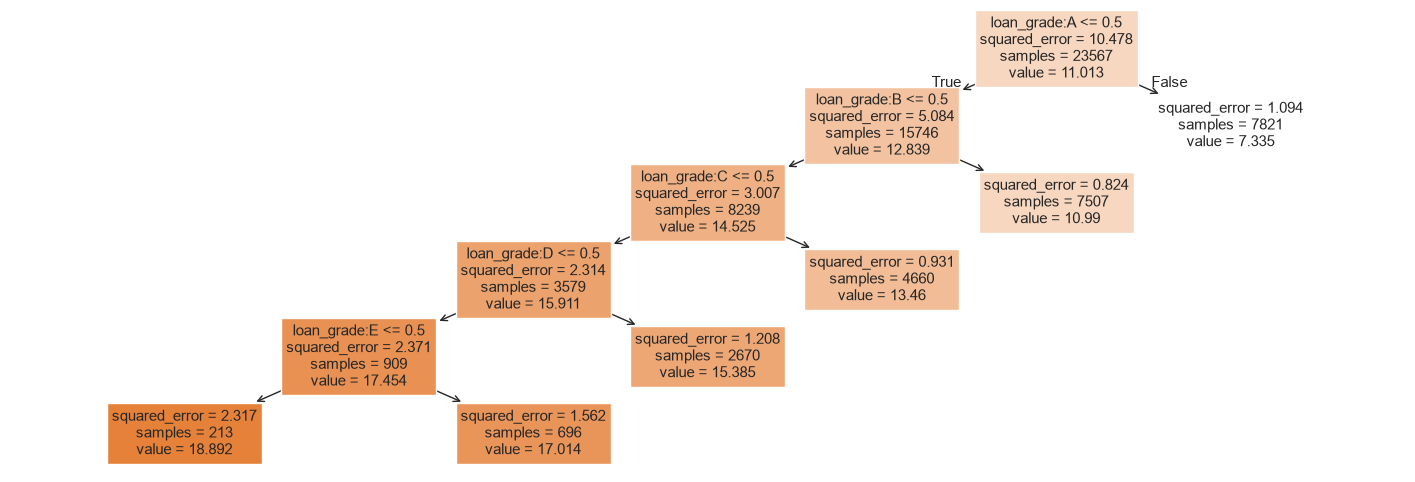

In [108]:
plt.figure(figsize=(18,6))
plot_tree(dcr, filled=True, feature_names= feature_name)


In [109]:
y_dcr_pred = dcr.predict(x_dcr_test)

<Axes: xlabel='loan_int_rate', ylabel='Count'>

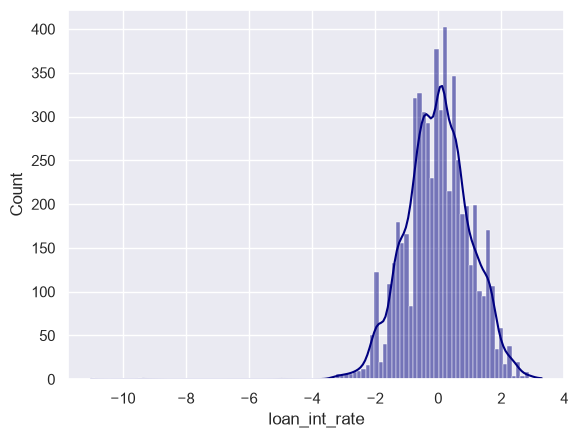

In [110]:
sns.histplot(y_dcr_test - y_dcr_pred, kde=True, color='Navy')

In [111]:
y_dcr_pred

array([ 7.33484337,  7.33484337,  7.33484337, ...,  7.33484337,
       10.98979619, 15.38529588], shape=(5892,))

In [112]:
dcr.score(x_dcr_test, y_dcr_test) #Model OK

0.9013209959984143

### Impute nulls

In [113]:
df_predict_dcr

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
38,23,71500,3.000,30000,NaN,0.420,0,4,0,0,...,0,0,0,0,0,0,1,0,0,0
49,24,78000,4.000,30000,NaN,0.380,1,4,0,0,...,0,0,0,0,0,0,1,0,0,0
56,23,277000,3.000,35000,NaN,0.130,0,4,0,0,...,0,1,0,1,0,0,0,0,0,0
58,24,12000,2.000,1750,NaN,0.150,1,3,0,0,...,0,0,1,0,0,0,0,1,0,0
61,26,263000,0.000,10000,NaN,0.040,0,4,1,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,0.000,1400,NaN,0.290,1,28,0,0,...,0,0,1,0,0,1,0,0,0,0
32545,65,45900,2.000,10000,NaN,0.220,1,19,0,0,...,0,0,0,0,0,1,0,0,0,0
32546,54,20000,2.000,5000,NaN,0.250,0,28,0,0,...,1,0,0,0,0,1,0,0,0,0
32562,51,60000,1.000,7500,NaN,0.130,0,23,1,0,...,0,1,0,1,0,0,0,0,0,0


In [114]:
x_null = df_predict_dcr.drop(['loan_int_rate'], axis=1)
y_null = pd.DataFrame(df_predict_dcr['loan_int_rate'], index=x_null.index)


In [115]:
x_null

,person_age,person_income,person_emp_length,loan_amnt,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership:MORTGAGE,person_home_ownership:OTHER,person_home_ownership:OWN,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
38,23,71500,3.000,30000,0.420,0,4,0,0,0,...,0,0,0,0,0,0,1,0,0,0
49,24,78000,4.000,30000,0.380,1,4,0,0,0,...,0,0,0,0,0,0,1,0,0,0
56,23,277000,3.000,35000,0.130,0,4,0,0,1,...,0,1,0,1,0,0,0,0,0,0
58,24,12000,2.000,1750,0.150,1,3,0,0,1,...,0,0,1,0,0,0,0,1,0,0
61,26,263000,0.000,10000,0.040,0,4,1,0,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,0.000,1400,0.290,1,28,0,0,1,...,0,0,1,0,0,1,0,0,0,0
32545,65,45900,2.000,10000,0.220,1,19,0,0,0,...,0,0,0,0,0,1,0,0,0,0
32546,54,20000,2.000,5000,0.250,0,28,0,0,0,...,1,0,0,0,0,1,0,0,0,0
32562,51,60000,1.000,7500,0.130,0,23,1,0,0,...,0,1,0,1,0,0,0,0,0,0


In [116]:
impute_pred = dcr.predict(x_null)

In [117]:
y_null['loan_int_rate'] = impute_pred

In [118]:
y_null

,loan_int_rate
38,15.385
49,15.385
56,7.335
58,17.014
61,10.990
...,...
32540,13.460
32545,13.460
32546,13.460
32562,7.335


In [119]:
loan_data[loan_data['loan_int_rate'].isnull()]

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
38,23,71500,RENT,3.000,DEBTCONSOLIDATION,D,30000,NaN,0.420,0,4,0
49,24,78000,RENT,4.000,DEBTCONSOLIDATION,D,30000,NaN,0.380,1,4,0
56,23,277000,OWN,3.000,PERSONAL,A,35000,NaN,0.130,0,4,1
58,24,12000,OWN,2.000,VENTURE,E,1750,NaN,0.150,1,3,1
61,26,263000,MORTGAGE,0.000,EDUCATION,B,10000,NaN,0.040,0,4,0
...,...,...,...,...,...,...,...,...,...,...,...,...
32540,53,4888,OWN,0.000,VENTURE,C,1400,NaN,0.290,1,28,0
32545,65,45900,RENT,2.000,EDUCATION,C,10000,NaN,0.220,1,19,1
32546,54,20000,RENT,2.000,MEDICAL,C,5000,NaN,0.250,0,28,1
32562,51,60000,MORTGAGE,1.000,PERSONAL,A,7500,NaN,0.130,0,23,1


In [120]:
loan_data['loan_int_rate'] = loan_data['loan_int_rate'].fillna(y_null['loan_int_rate'])

In [121]:
loan_data.loc[y_null.index, 'loan_int_rate'] #Impute OK

38      15.385
49      15.385
56       7.335
58      17.014
61      10.990
         ...  
32540   13.460
32545   13.460
32546   13.460
32562    7.335
32563   10.990
Name: loan_int_rate, Length: 3115, dtype: float64

In [122]:
loan_data_cleaned = loan_data
loan_data_cleaned

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0.100,0,2,1
1,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,0.570,0,3,0
2,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,0.530,0,2,0
3,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,0.550,1,4,0
4,21,9900,OWN,2.000,VENTURE,A,2500,7.140,0.250,0,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...
32569,57,53000,MORTGAGE,1.000,PERSONAL,C,5800,13.160,0.110,0,30,1
32570,54,120000,MORTGAGE,4.000,PERSONAL,A,17625,7.490,0.150,0,19,1
32571,65,76000,RENT,3.000,HOMEIMPROVEMENT,B,35000,10.990,0.460,0,28,0
32572,56,150000,MORTGAGE,5.000,PERSONAL,B,15000,11.480,0.100,0,26,1


### Create dummies

In [123]:
loan_data_dummies = create_dummies(loan_data_cleaned, features_dummies)

In [124]:
loan_data_cleaned = pd.concat([loan_data_cleaned, loan_data_dummies], axis=1)

In [125]:
loan_data_cleaned

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
0,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0.100,0,...,0,0,0,0,1,0,0,0,0,0
1,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,0.570,0,...,1,0,0,0,0,1,0,0,0,0
2,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,0.530,0,...,1,0,0,0,0,1,0,0,0,0
3,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,0.550,1,...,1,0,0,0,0,1,0,0,0,0
4,21,9900,OWN,2.000,VENTURE,A,2500,7.140,0.250,0,...,0,0,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32569,57,53000,MORTGAGE,1.000,PERSONAL,C,5800,13.160,0.110,0,...,0,1,0,0,0,1,0,0,0,0
32570,54,120000,MORTGAGE,4.000,PERSONAL,A,17625,7.490,0.150,0,...,0,1,0,1,0,0,0,0,0,0
32571,65,76000,RENT,3.000,HOMEIMPROVEMENT,B,35000,10.990,0.460,0,...,0,0,0,0,1,0,0,0,0,0
32572,56,150000,MORTGAGE,5.000,PERSONAL,B,15000,11.480,0.100,0,...,0,1,0,0,1,0,0,0,0,0


In [126]:
loan_data_cleaned

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,...,loan_intent:MEDICAL,loan_intent:PERSONAL,loan_intent:VENTURE,loan_grade:A,loan_grade:B,loan_grade:C,loan_grade:D,loan_grade:E,loan_grade:F,loan_grade:G
0,21,9600,OWN,5.000,EDUCATION,B,1000,11.140,0.100,0,...,0,0,0,0,1,0,0,0,0,0
1,25,9600,MORTGAGE,1.000,MEDICAL,C,5500,12.870,0.570,0,...,1,0,0,0,0,1,0,0,0,0
2,23,65500,RENT,4.000,MEDICAL,C,35000,15.230,0.530,0,...,1,0,0,0,0,1,0,0,0,0
3,24,54400,RENT,8.000,MEDICAL,C,35000,14.270,0.550,1,...,1,0,0,0,0,1,0,0,0,0
4,21,9900,OWN,2.000,VENTURE,A,2500,7.140,0.250,0,...,0,0,1,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32569,57,53000,MORTGAGE,1.000,PERSONAL,C,5800,13.160,0.110,0,...,0,1,0,0,0,1,0,0,0,0
32570,54,120000,MORTGAGE,4.000,PERSONAL,A,17625,7.490,0.150,0,...,0,1,0,1,0,0,0,0,0,0
32571,65,76000,RENT,3.000,HOMEIMPROVEMENT,B,35000,10.990,0.460,0,...,0,0,0,0,1,0,0,0,0,0
32572,56,150000,MORTGAGE,5.000,PERSONAL,B,15000,11.480,0.100,0,...,0,1,0,0,1,0,0,0,0,0


### Save preprocessed data

In [127]:
# loan_data_cleaned.to_csv('Preprocessed.csv')

### Split data

In [61]:
x_train, x_test, y_train, y_test = train_test_split(loan_data_cleaned.drop('loan_status', axis =1),
                                                    loan_data_cleaned['loan_status'], test_size= 0.2, random_state=42)

In [62]:
x_prep = x_train
y_prep = y_train
#x_prep = x_test
#y_prep = y_test

In [64]:
x_prep.shape

(26059, 28)

### WOE calculation

### WOE functions

In [87]:
def x_WoE_discrete(df, x, y):
    df_data = pd.concat([df[x], y], axis=1)
    temp = pd.concat([df_data.groupby(df_data[x], as_index = False)['loan_status'].count(),
                      df_data.groupby(df_data[x], as_index = False)['loan_status'].mean()], axis=1)
    temp = temp.iloc[:, [0,1,3]]
    temp.columns = ['categories', 'n_observations', 'pct_good']
    temp.insert(loc = 2, column = 'pct_observations', value = temp['n_observations']/temp['n_observations'].sum())
    temp['pct_bad'] = 1 - temp['pct_good']
    temp['n_good'] = temp['pct_good'] * temp['n_observations']
    temp['n_bad'] = (1 - temp['pct_good']) * temp['n_observations']
    temp['pct_n_good'] = temp['n_good'] / temp['n_good'].sum()
    temp['pct_n_bad'] = temp['n_bad'] / temp['n_bad'].sum()
    temp['WoE'] = np.log(temp['pct_n_good']/temp['pct_n_bad'])
    temp = temp.sort_values('WoE', ascending=True)
    temp = temp.reset_index(drop = True)
    temp['IV'] = (temp['pct_n_good'] - temp['pct_n_bad']) * temp['WoE']
    temp['IV'] = temp['IV'].sum()
    # temp = temp.style.set_properties(**{'background-color': 'yellow'}, subset=['IV'])
    return temp

In [88]:
features_dummies

['person_home_ownership', 'loan_intent', 'loan_grade']

In [89]:
results_discrete = x_WoE_discrete(x_prep, 'loan_grade', y_prep)

C:\Users\admin\anaconda3\Lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [90]:
results_discrete

,categories,n_observations,pct_observations,pct_good,pct_bad,n_good,n_bad,pct_n_good,pct_n_bad,WoE,IV
0,G,16,0.002,0.000,1.000,0.000,16.000,0.000,0.011,-inf,inf
1,F,51,0.008,0.333,0.667,17.000,34.000,0.003,0.024,-1.974,inf
2,E,181,0.028,0.359,0.641,65.000,116.000,0.013,0.082,-1.860,inf
3,D,723,0.111,0.405,0.595,293.000,430.000,0.057,0.304,-1.665,inf
4,C,1288,0.198,0.795,0.205,1024.000,264.000,0.201,0.186,0.074,inf
5,B,2107,0.323,0.834,0.166,1757.000,350.000,0.345,0.247,0.332,inf
6,A,2149,0.330,0.904,0.096,1943.000,206.000,0.381,0.145,0.963,inf


In [91]:
x_prep['person_home_ownership:RENT_OTHER'] = sum([x_prep['person_home_ownership:RENT'], x_prep['person_home_ownership:OTHER']])

### Fine & Coarse classing continuous variables

In [92]:
def x_WoE_continuous(df, x, y):
    df_data = pd.concat([df[x], y], axis=1)
    temp = pd.concat([df_data.groupby(df_data[x], as_index = False)['loan_status'].count(),
                      df_data.groupby(df_data[x], as_index = False)['loan_status'].mean()], axis=1)
    temp = temp.iloc[:, [0,1,3]]
    temp.columns = ['bins', 'n_observations', 'pct_good']
    temp.insert(loc = 2, column = 'pct_observations', value = temp['n_observations']/temp['n_observations'].sum())
    temp['pct_bad'] = 1 - temp['pct_good']
    temp['n_good'] = temp['pct_good'] * temp['n_observations']
    temp['n_bad'] = (1 - temp['pct_good']) * temp['n_observations']
    temp['pct_n_good'] = temp['n_good'] / temp['n_good'].sum()
    temp['pct_n_bad'] = temp['n_bad'] / temp['n_bad'].sum()
    temp['WoE'] = np.log(temp['pct_n_good']/temp['pct_n_bad'])
    #temp = temp.sort_values('WoE', ascending=True)
    #temp = temp.reset_index(drop = True)
    temp['IV'] = (temp['pct_n_good'] - temp['pct_n_bad']) * temp['WoE']
    temp['IV'] = temp['IV'].sum()
    # temp = temp.style.set_properties(**{'background-color': 'yellow'}, subset=['IV'])
    return temp

In [93]:
x_prep['person_age_factor'] = pd.cut(x_prep['person_age'], bins=10)

In [94]:
x_prep['person_age:20-30'] = np.where(x_prep['person_age'].isin(range(20, 31)), 1, 0)
x_prep['person_age:31-50'] = np.where(x_prep['person_age'].isin(range(31, 51)), 1, 0)
x_prep['person_age:>50'] = np.where(x_prep['person_age'].isin(range(51, int(x_prep['person_age'].max()))), 1, 0)

In [95]:
x_prep['person_emp_length_factor'] = pd.qcut(x_prep['person_emp_length'], q=6)

In [96]:
x_prep['person_emp_length:<1'] = np.where((x_prep['person_emp_length'] < 1), 1, 0)
x_prep['person_emp_length:1-2'] = np.where((x_prep['person_emp_length'] >= 1) & 
                                           (x_prep['person_emp_length'] < 2), 1, 0)
x_prep['person_emp_length:2-4'] = np.where((x_prep['person_emp_length'] >= 2) & 
                                           (x_prep['person_emp_length'] < 4), 1, 0)
x_prep['person_emp_length:4-6'] = np.where((x_prep['person_emp_length'] >= 4) & 
                                           (x_prep['person_emp_length'] < 6), 1, 0)
x_prep['person_emp_length:6-8'] = np.where((x_prep['person_emp_length'] >= 6) & 
                                           (x_prep['person_emp_length'] < 8), 1, 0)
x_prep['person_emp_length:>=8'] = np.where((x_prep['person_emp_length'] >= 8), 1, 0)

In [97]:
x_prep['loan_int_rate_factor'] = pd.qcut(x_prep['loan_int_rate'], q=3)

In [98]:
x_prep['loan_int_rate:<9.45'] = np.where((x_prep['loan_int_rate'] <= 9.45), 1, 0)
x_prep['loan_int_rate:9.45-12.68'] = np.where((x_prep['loan_int_rate'] > 9.45) & (x_prep['loan_int_rate'] <=12.68), 1, 0)
x_prep['loan_int_rate:>12.68'] = np.where((x_prep['loan_int_rate'] > 12.68), 1, 0)

In [99]:
x_prep['cb_person_cred_hist_length_factor'] = pd.qcut(x_prep['cb_person_cred_hist_length'],q=5)

In [100]:
x_prep['cb_person_cred_hist_length:<=3'] = np.where((x_prep['cb_person_cred_hist_length'] <= 3), 1, 0)
x_prep['cb_person_cred_hist_length:3-4'] = np.where((x_prep['cb_person_cred_hist_length'] > 3) & 
                                                    (x_prep['cb_person_cred_hist_length'] <= 4), 1, 0)
x_prep['cb_person_cred_hist_length:4-9'] = np.where((x_prep['cb_person_cred_hist_length'] > 4) & 
                                                    (x_prep['cb_person_cred_hist_length'] <= 9), 1, 0)
x_prep['cb_person_cred_hist_length:>9'] = np.where((x_prep['cb_person_cred_hist_length'] > 9), 1, 0)

In [101]:
x_prep_temp = x_prep.loc[x_prep['person_income'] < 130000, :]

In [102]:
x_prep_temp['person_income_factor'] = pd.qcut(x_prep_temp['person_income'], q = 15)

In [103]:
x_prep['person_income:<25000'] = np.where((x_prep['person_income'] <= 25000), 1, 0)
x_prep['person_income:25k-35k'] = np.where((x_prep['person_income'] > 25000) & (x_prep['person_income'] <= 35000), 1, 0)
x_prep['person_income:35k-45k'] = np.where((x_prep['person_income'] > 35000) & (x_prep['person_income'] <= 45000), 1, 0)
x_prep['person_income:45k-55k'] = np.where((x_prep['person_income'] > 45000) & (x_prep['person_income'] <= 55000), 1, 0)
x_prep['person_income:55k-63k'] = np.where((x_prep['person_income'] > 55000) & (x_prep['person_income'] <= 65000), 1, 0)
x_prep['person_income:63k-73k'] = np.where((x_prep['person_income'] > 63000) & (x_prep['person_income'] <= 73000), 1, 0)
x_prep['person_income:73k-80k'] = np.where((x_prep['person_income'] > 73000) & (x_prep['person_income'] <= 80000), 1, 0)
x_prep['person_income:80k-100k'] = np.where((x_prep['person_income'] > 80000) & (x_prep['person_income'] <= 100000), 1, 0)
x_prep['person_income:100k-130k'] = np.where((x_prep['person_income'] > 100000) & (x_prep['person_income'] <= 130000), 1, 0)
x_prep['person_income:>130000'] = np.where((x_prep['person_income'] > 130000), 1, 0)

In [104]:
x_prep['loan_percent_income_factor']= pd.qcut(x_prep['loan_percent_income'], q=10)

In [105]:
x_prep['loan_percent_income:<0.07'] = np.where((x_prep['loan_percent_income'] < 0.07), 1, 0)
x_prep['loan_percent_income:0.07-0.12'] = np.where((x_prep['loan_percent_income'] >= 0.07) & 
                                                   (x_prep['loan_percent_income'] < 0.12), 1, 0)
x_prep['loan_percent_income:0.12-0.15'] = np.where((x_prep['loan_percent_income'] >= 0.12) & 
                                                   (x_prep['loan_percent_income'] < 0.15), 1, 0)
x_prep['loan_percent_income:0.15-0.25'] = np.where((x_prep['loan_percent_income'] >= 0.15) & 
                                                   (x_prep['loan_percent_income'] <= 0.25), 1, 0)
x_prep['loan_percent_income:>0.25'] = np.where((x_prep['loan_percent_income'] > 0.25), 1, 0)

In [106]:
x_prep.shape # Preprocessing done!

(6515, 65)

In [96]:
df_temp = x_WoE_continuous(x_prep, 'loan_int_rate_factor', y_prep)

In [97]:
df_temp

,bins,n_observations,pct_observations,pct_good,pct_bad,n_good,n_bad,pct_n_good,pct_n_bad,WoE,IV
0,"(5.419, 9.45]",8719,0.335,0.899,0.101,7835.000,884.000,0.385,0.155,0.907,0.509
1,"(9.45, 12.68]",8748,0.336,0.832,0.168,7277.000,1471.000,0.357,0.258,0.324,0.509
2,"(12.68, 23.22]",8592,0.330,0.612,0.388,5256.000,3336.000,0.258,0.586,-0.820,0.509


### Preprocess test data

In [ ]:
#x_prep = x_test
#y_prep = y_test

### Overwrite train & test data

In [107]:
#x_train = x_prep
#x_test = x_prep

### Save train & test data

In [108]:
"""x_train.to_csv('x_train.csv')
x_test.to_csv('x_test.csv')
y_train.to_csv('y_train.csv')
y_test.to_csv('y_test.csv')"""

### Plot WoE

In [98]:
def plot_WoE(df, rotation_x_labels = 0):
    x = np.array(df.iloc[:, 0].apply(str))
    y = df['WoE']
    plt.figure(figsize=(18,6))
    plt.plot(x,y, linestyle = '--', marker = 'o')
    plt.xlabel(df.columns[0])
    plt.ylabel('Weight of Evidence')
    plt.title(str('WoE by ' + df.columns[0]))
    plt.xticks(rotation = rotation_x_labels)

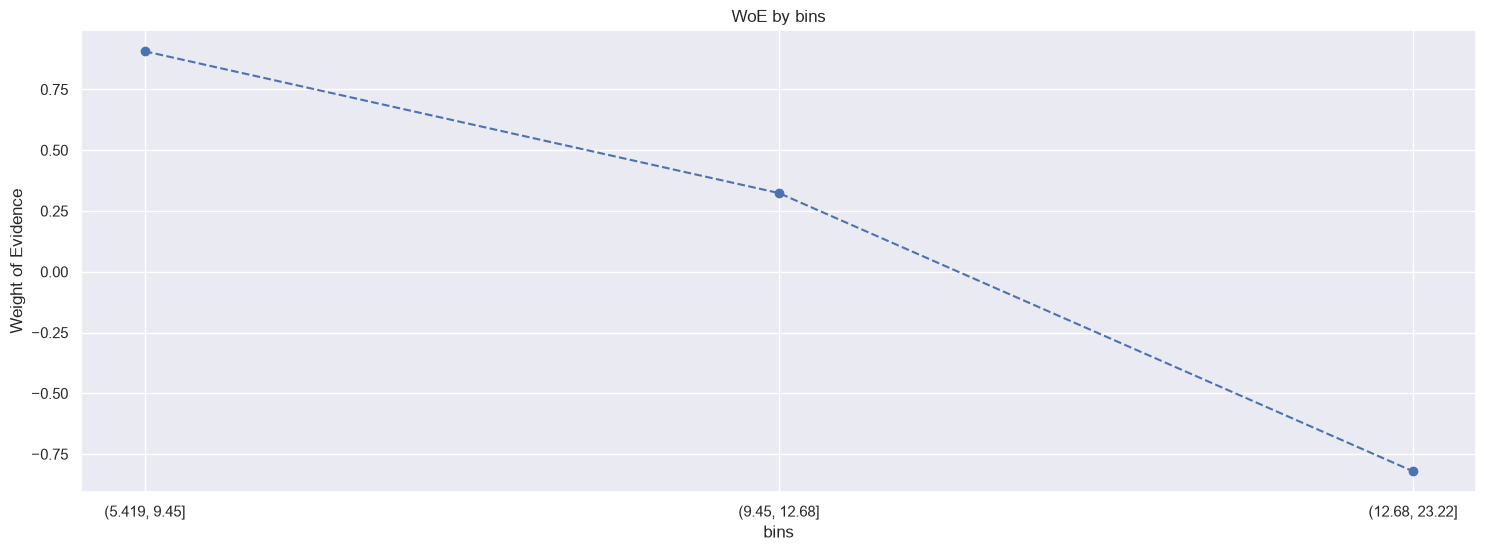

In [99]:
plot_WoE(df_temp)

### ------Check data-------

In [87]:
loan_data_cleaned.columns

Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length', 'loan_status',
       'person_home_ownership:MORTGAGE', 'person_home_ownership:OTHER',
       'person_home_ownership:OWN', 'person_home_ownership:RENT',
       'loan_intent:DEBTCONSOLIDATION', 'loan_intent:EDUCATION',
       'loan_intent:HOMEIMPROVEMENT', 'loan_intent:MEDICAL',
       'loan_intent:PERSONAL', 'loan_intent:VENTURE', 'loan_grade:A',
       'loan_grade:B', 'loan_grade:C', 'loan_grade:D', 'loan_grade:E',
       'loan_grade:F', 'loan_grade:G'],
      dtype='str')

<Axes: xlabel='loan_int_rate', ylabel='Count'>

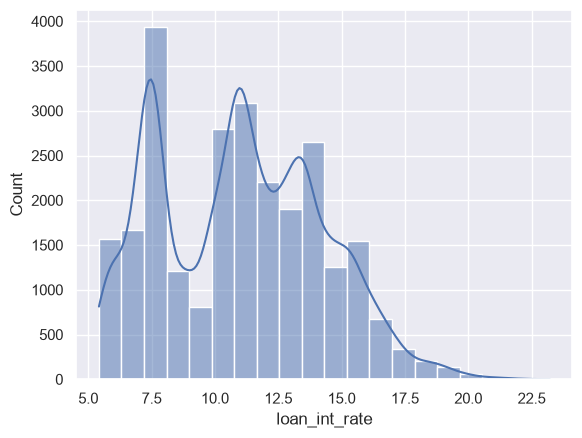

In [88]:
sns.histplot(x_prep['loan_int_rate'],bins=20, kde=True)


In [90]:
def percentile_exc(data, q):
    arr = np.sort(np.asarray(data))
    n = len(arr)
    k = q / 100.0

    # Excel's EXC position formula
    pos = k * (n + 1)
    if pos < 1 or pos > n:
        raise ValueError("Percentile out of bounds for PERCENTILE.EXC given the array size.")
    i = int(np.floor(pos))
    g = pos - i
    if g == 0:
        return arr[i - 1]
    else:
        # Linear interpolation between the surrounding elements
        return arr[i - 1] + g * (arr[i] - arr[i - 1])


In [94]:
percentile_exc(loan_data_cleaned['loan_int_rate'], 30)

np.float64(8.88)